# Washington Electric Vehicle Population Analysis

An exploratory analysis of electric vehicle registrations, examining
manufacturer popularity, geographic distribution, recorded electric
ranges, and model-year patterns.

The analysis also evaluates data quality and documents limitations
that affect interpretation.

## Data Loading

In [1]:
from pathlib import Path

import pandas as pd

# Support execution from either the project root or notebooks folder.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "EV_Population_WA_Data.csv"

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")

Dataset loaded: 200,048 rows × 17 columns


## Initial Data Inspection

In [2]:
# First few rows of the dataset
df.head()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 Census Tract
0,5YJ3E1EB0J,Thurston,Olympia,WA,98512.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215,0,35.0,104823078,POINT (-122.957046 46.991391),PUGET SOUND ENERGY INC,5.306701e+10
1,WA1AAAGE9M,Kitsap,Port Orchard,WA,98367.0,2021,AUDI,E-TRON,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,222,0,35.0,156660507,POINT (-122.6530052 47.4739066),PUGET SOUND ENERGY INC,5.303509e+10
2,5YJ3E1EA2J,Yakima,Yakima,WA,98902.0,2018,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,215,0,14.0,269374108,POINT (-120.530331 46.59534),PACIFICORP,5.307700e+10
3,5YJ3E1EA4N,Yakima,Yakima,WA,98902.0,2022,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0,0,15.0,213383894,POINT (-120.530331 46.59534),PACIFICORP,5.307700e+10
4,7SAYGAEE2P,Snohomish,Bothell,WA,98012.0,2023,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0,0,1.0,229496046,POINT (-122.206146 47.839957),PUGET SOUND ENERGY INC,5.306105e+10


In [3]:
# Column and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200048 entries, 0 to 200047
Data columns (total 17 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         200048 non-null  object 
 1   County                                             200044 non-null  object 
 2   City                                               200044 non-null  object 
 3   State                                              200048 non-null  object 
 4   Postal Code                                        200044 non-null  float64
 5   Model Year                                         200048 non-null  int64  
 6   Make                                               200048 non-null  object 
 7   Model                                              200048 non-null  object 
 8   Electric Vehicle Type                              200048 non-null  object

In [4]:
# Descriptive statistics
df.describe()

,Postal Code,Model Year,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,2020 Census Tract
count,200044.000000,200048.000000,200048.000000,200048.000000,199606.000000,2.000480e+05,2.000440e+05
mean,98176.178121,2020.871261,53.485279,947.551913,28.986063,2.262988e+08,5.297545e+10
std,2424.207811,2.994933,88.786301,7860.591091,14.908108,7.282433e+07,1.605628e+09
min,1731.000000,1997.000000,0.000000,0.000000,1.000000,4.385000e+03,1.001020e+09
25%,98052.000000,2019.000000,0.000000,0.000000,17.000000,1.904573e+08,5.303301e+10
50%,98125.000000,2022.000000,0.000000,0.000000,33.000000,2.363396e+08,5.303303e+10
75%,98372.000000,2023.000000,53.000000,0.000000,42.000000,2.609659e+08,5.305307e+10
max,99577.000000,2025.000000,337.000000,845000.000000,49.000000,4.792548e+08,5.602100e+10


In [5]:
# Shape of the dataset
df.shape

(200048, 17)

In [6]:
# Checking for missing values
missing_values = df.isnull().sum()
missing_values

VIN (1-10)                                             0
County                                                 4
City                                                   4
State                                                  0
Postal Code                                            4
Model Year                                             0
Make                                                   0
Model                                                  0
Electric Vehicle Type                                  0
Clean Alternative Fuel Vehicle (CAFV) Eligibility      0
Electric Range                                         0
Base MSRP                                              0
Legislative District                                 442
DOL Vehicle ID                                         0
Vehicle Location                                       8
Electric Utility                                       4
2020 Census Tract                                      4
dtype: int64

The dataset contains 200,048 records with 17 columns, including details about electric vehicles such as manufacturer, model, year, electric range, and location. Some columns have missing values, such as County, City, Postal Code, Legislative District, Vehicle Location, Electric Utility, and Census Tract.

## Data Cleaning

In [7]:
# Preserve the original dataset.
df_raw = df.copy()

# Focus the analysis on vehicles with a Washington address.
df = df_raw.loc[df_raw["State"].eq("WA")].copy()

# Preserve missing geographic values rather than inventing replacements.
for column in ["Postal Code", "Legislative District", "2020 Census Tract"]:
    df[column] = df[column].astype("Int64")

# Keep recorded values and create separate fields for analysis.
# Zero electric range indicates that range has not been researched.
df["Electric Range Known"] = df["Electric Range"].where(
    df["Electric Range"] > 0
)

# Zero MSRP is unavailable pricing information, not a free vehicle.
df["Base MSRP Known"] = df["Base MSRP"].where(
    df["Base MSRP"] > 0
)

print(f"Original records: {len(df_raw):,}")
print(f"Washington records: {len(df):,}")
print(f"Records outside Washington: {len(df_raw) - len(df):,}")
print(f"Known positive ranges: {df['Electric Range Known'].notna().sum():,}")
print(f"Available positive MSRP values: {df['Base MSRP Known'].notna().sum():,}")

Original records: 200,048
Washington records: 199,606
Records outside Washington: 442
Known positive ranges: 90,413
Available positive MSRP values: 3,311


### Data Cleaning Decisions

- The raw dataset is preserved in `df_raw`.
- Analysis is restricted to records with a Washington address (`State = WA`).
- Missing geographic values remain missing; no district or location is imputed.
- Postal codes, legislative districts, and census tracts use nullable integer types.
- Recorded zero electric ranges represent unresearched ranges. A separate
  `Electric Range Known` column excludes these values from range statistics.
- A separate `Base MSRP Known` column excludes zero prices. Pricing coverage
  is limited, so price comparisons require caution.
- Positive ranges and prices are retained for inspection rather than removed
  automatically as statistical outliers.

In [8]:
# Check duplicates and remaining missing values.
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(
    "Duplicate vehicle IDs: "
    f"{df['DOL Vehicle ID'].duplicated().sum():,}"
)

quality_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing (%)": df.isna().mean().mul(100).round(2),
})

display(
    quality_summary.loc[quality_summary["Missing Count"] > 0]
    .sort_values("Missing Count", ascending=False)
)

Duplicate rows: 0
Duplicate vehicle IDs: 0


,Missing Count,Missing (%)
Base MSRP Known,196295,98.34
Electric Range Known,109193,54.70
Vehicle Location,4,0.00


### Recorded Electric Range Distribution

Range statistics use positive, researched values only. Battery electric
vehicles (BEVs) and plug-in hybrids (PHEVs) are shown separately because
their electric-only ranges differ.

These results describe vehicles with available range information, which
may not represent the full registered EV population. Extreme values are
inspected rather than automatically removed.

In [9]:
# Importing necessary libraries for visualization and analysis
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")

,count,mean,std,min,25%,50%,75%,max
Vehicle Type,,,,,,,,
BEV,47447.0,196.9,73.0,29.0,149.0,215.0,238.0,337.0
PHEV,42966.0,31.0,15.1,6.0,21.0,30.0,38.0,153.0


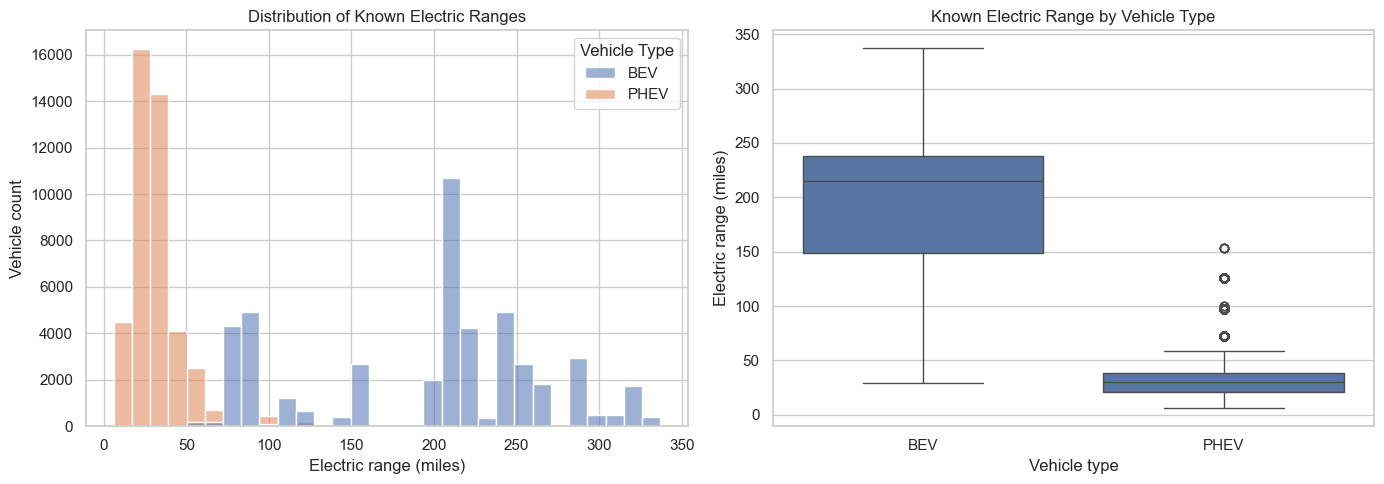

In [10]:
# Analyzing Electric Range Data

range_df = df.loc[df["Electric Range Known"].notna()].copy()

vehicle_type_labels = {
    "Battery Electric Vehicle (BEV)": "BEV",
    "Plug-in Hybrid Electric Vehicle (PHEV)": "PHEV",
}

range_df["Vehicle Type"] = range_df["Electric Vehicle Type"].map(
    vehicle_type_labels
)

display(
    range_df.groupby("Vehicle Type")["Electric Range Known"]
    .describe()
    .round(1)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=range_df,
    x="Electric Range Known",
    hue="Vehicle Type",
    hue_order=["BEV", "PHEV"],
    bins=30,
    multiple="layer",
    alpha=0.55,
    ax=axes[0],
)
axes[0].set(
    title="Distribution of Known Electric Ranges",
    xlabel="Electric range (miles)",
    ylabel="Vehicle count",
)

sns.boxplot(
    data=range_df,
    x="Vehicle Type",
    y="Electric Range Known",
    order=["BEV", "PHEV"],
    ax=axes[1],
)
axes[1].set(
    title="Known Electric Range by Vehicle Type",
    xlabel="Vehicle type",
    ylabel="Electric range (miles)",
)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "known_range_distribution.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

### Base MSRP Coverage and Limitations

Positive Base MSRP values are available for only about 1.66% of
Washington records. This small subset may not represent the overall
vehicle population, so pricing results cannot be generalized to all EVs.

Zero values are excluded from price statistics. Positive values are
retained, including unusually high prices, for inspection.

In [11]:
# Analyzing MSRP Data

msrp_df = df.loc[df["Base MSRP Known"].notna()].copy()

print(f"Records with positive MSRP: {len(msrp_df):,}")
print(f"MSRP coverage: {len(msrp_df) / len(df):.2%}")

display(
    msrp_df["Base MSRP Known"]
    .describe()
    .round(2)
    .to_frame(name="Base MSRP ($)")
)

# Inspect the highest recorded prices without displaying repeated entries.
display(
    msrp_df[
        ["Make", "Model", "Model Year", "Base MSRP Known"]
    ]
    .drop_duplicates()
    .sort_values("Base MSRP Known", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

Records with positive MSRP: 3,311
MSRP coverage: 1.66%


,Base MSRP ($)
count,3311.00
mean,57055.54
std,22770.76
min,31950.00
25%,39995.00
50%,59900.00
75%,69900.00
max,845000.00


,Make,Model,Model Year,Base MSRP Known
0,PORSCHE,918,2015,845000.0
1,PORSCHE,PANAMERA,2018,184400.0
2,TESLA,ROADSTER,2010,110950.0
3,TESLA,ROADSTER,2011,109000.0
4,FISKER,KARMA,2012,102000.0
5,TESLA,ROADSTER,2008,98950.0
6,BMW,740E,2019,91250.0
7,BMW,740E,2018,90700.0
8,BMW,740E,2017,89100.0
9,PORSCHE,CAYENNE,2020,81100.0


### Findings from Range and Pricing Inspection

- Among vehicles with researched range, BEVs have a median electric
  range of 215 miles, compared with 30 miles for PHEVs.
- These are recorded electric-only ranges, not total driving ranges.
- Range information is unavailable for 54.70% of Washington records,
  limiting conclusions about the full population.
- MSRP coverage is too limited to support broad claims about EV
  affordability or the relationship between price and range.

## Manufacturer, Model, and City Distribution

### Most Common Manufacturers

,Manufacturer,Vehicle Count,Share (%)
0,TESLA,87860,44.02
1,CHEVROLET,14781,7.41
2,NISSAN,14404,7.22
3,FORD,10518,5.27
4,KIA,8752,4.38
5,BMW,8282,4.15
6,TOYOTA,7655,3.84
7,VOLKSWAGEN,5552,2.78
8,HYUNDAI,5469,2.74
9,JEEP,5272,2.64


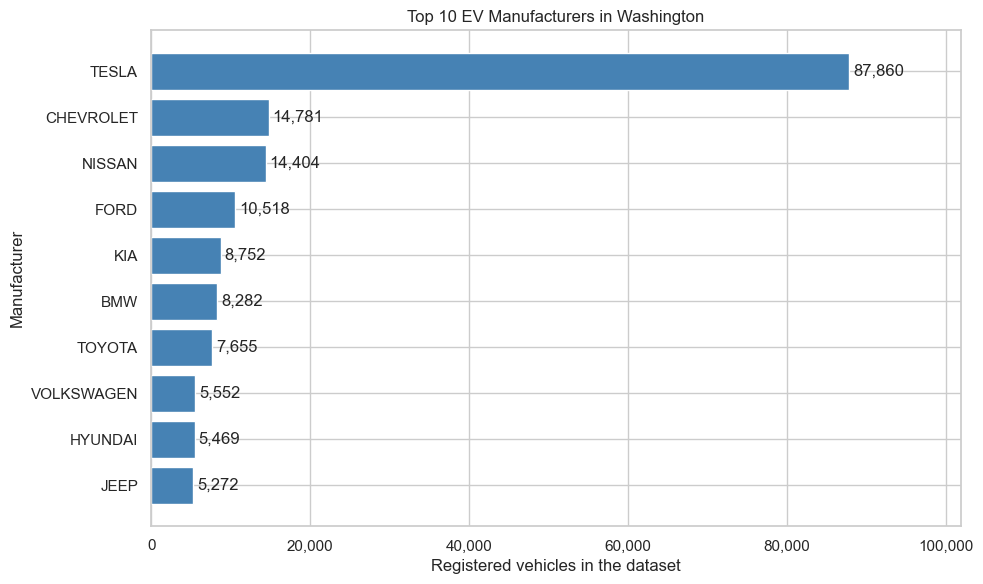

In [12]:
# Manufacturer Analysis

manufacturer_summary = (
    df["Make"]
    .value_counts()
    .rename_axis("Manufacturer")
    .reset_index(name="Vehicle Count")
)

manufacturer_summary["Share (%)"] = (
    manufacturer_summary["Vehicle Count"] / len(df) * 100
).round(2)

display(manufacturer_summary.head(10))

top_manufacturers = manufacturer_summary.head(10)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_manufacturers["Manufacturer"],
    top_manufacturers["Vehicle Count"],
    color="steelblue",
)
ax.invert_yaxis()

ax.set(
    title="Top 10 EV Manufacturers in Washington",
    xlabel="Registered vehicles in the dataset",
    ylabel="Manufacturer",
)

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:,.0f}")
)

for position, count in enumerate(top_manufacturers["Vehicle Count"]):
    ax.text(count + 500, position, f"{count:,}", va="center")

ax.set_xlim(0, top_manufacturers["Vehicle Count"].max() * 1.16)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "top_manufacturers.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

### Manufacturer Findings

Tesla has the largest vehicle count in this Washington dataset,
followed by Chevrolet, Nissan, Ford, and Kia.

The percentages describe each manufacturer's share of the EV records
in this snapshot. They do not measure annual sales or share of all
vehicles on Washington roads.

### Most Common EV Models

Vehicles are grouped by manufacturer and model. Counts combine model
years and vehicle variants within each make-model pair.

,Make,Model,Vehicle Count,Share (%)
0,TESLA,MODEL Y,41893,20.99
1,TESLA,MODEL 3,31513,15.79
2,NISSAN,LEAF,13484,6.76
3,TESLA,MODEL S,7847,3.93
4,CHEVROLET,BOLT EV,6636,3.32
5,TESLA,MODEL X,6174,3.09
6,CHEVROLET,VOLT,4819,2.41
7,VOLKSWAGEN,ID.4,4473,2.24
8,FORD,MUSTANG MACH-E,3972,1.99
9,JEEP,WRANGLER,3935,1.97


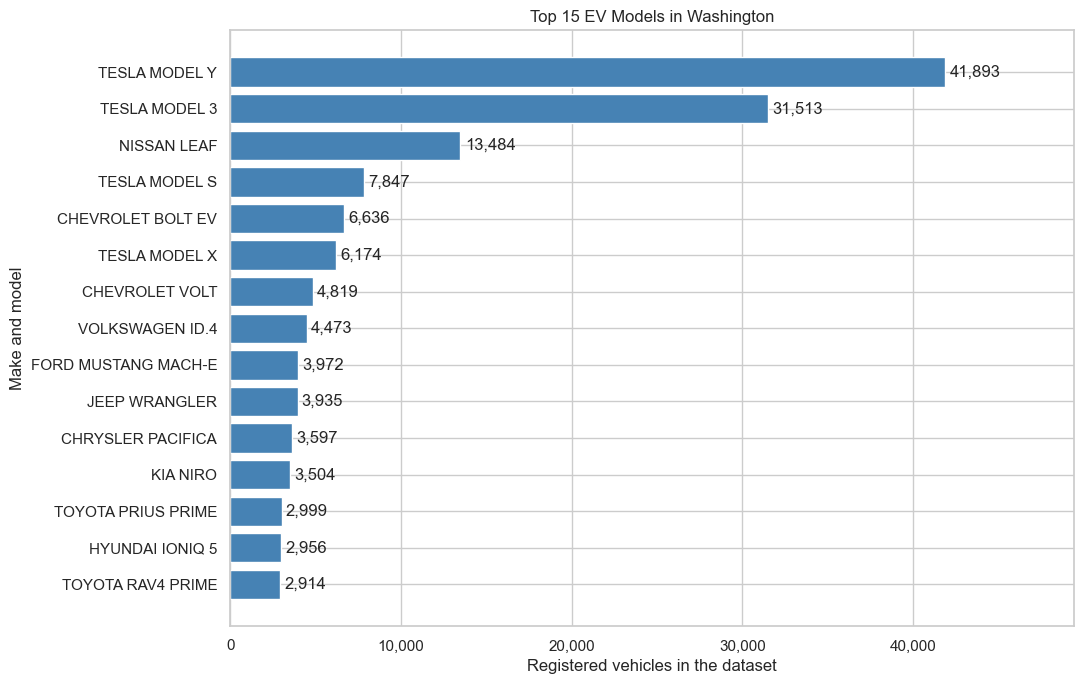

In [13]:
# Model Analysis

model_summary = (
    df.groupby(["Make", "Model"])
    .size()
    .reset_index(name="Vehicle Count")
    .sort_values(
        ["Vehicle Count", "Make", "Model"],
        ascending=[False, True, True],
    )
    .reset_index(drop=True)
)

model_summary["Share (%)"] = (
    model_summary["Vehicle Count"] / len(df) * 100
).round(2)

model_summary["Vehicle Model"] = (
    model_summary["Make"] + " " + model_summary["Model"]
)

display(
    model_summary[
        ["Make", "Model", "Vehicle Count", "Share (%)"]
    ].head(15)
)

top_models = model_summary.head(15)

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    top_models["Vehicle Model"],
    top_models["Vehicle Count"],
    color="steelblue",
)
ax.invert_yaxis()

ax.set(
    title="Top 15 EV Models in Washington",
    xlabel="Registered vehicles in the dataset",
    ylabel="Make and model",
)

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:,.0f}")
)

for position, count in enumerate(top_models["Vehicle Count"]):
    ax.text(count + 250, position, f"{count:,}", va="center")

ax.set_xlim(0, top_models["Vehicle Count"].max() * 1.18)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "top_models.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

### Cities with the Most EVs

City totals describe the geographic distribution of EVs in this
Washington snapshot. They are absolute counts, not adoption rates:
population or total vehicle counts would be needed for that comparison.

,City,Vehicle Count,Share (%)
0,Seattle,32602,16.33
1,Bellevue,9959,4.99
2,Redmond,7165,3.59
3,Vancouver,7081,3.55
4,Bothell,6602,3.31
5,Kirkland,5883,2.95
6,Renton,5835,2.92
7,Sammamish,5795,2.90
8,Olympia,4830,2.42
9,Tacoma,4204,2.11


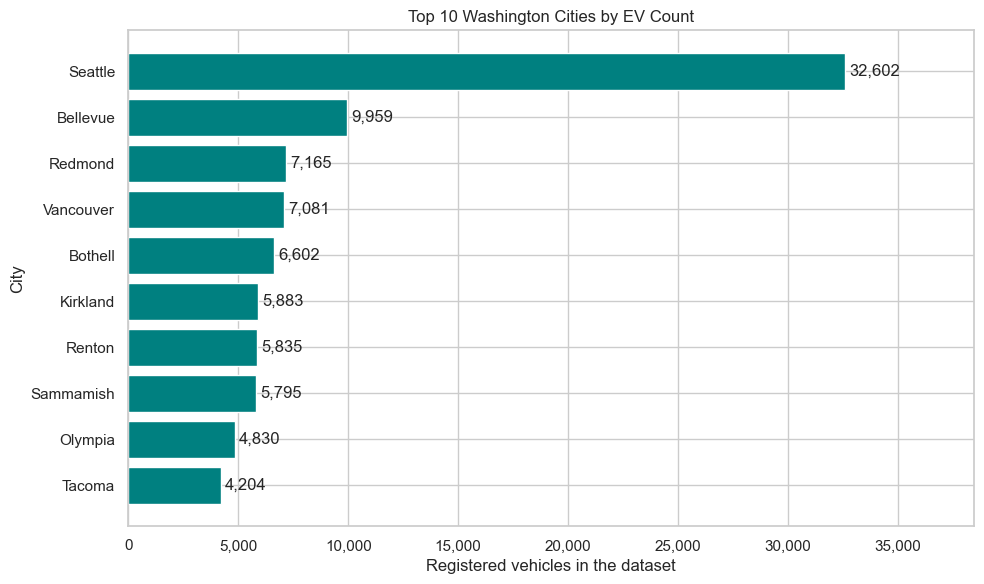

In [14]:
# City Analysis

city_summary = (
    df["City"]
    .value_counts()
    .rename_axis("City")
    .reset_index(name="Vehicle Count")
)

city_summary["Share (%)"] = (
    city_summary["Vehicle Count"] / len(df) * 100
).round(2)

display(city_summary.head(10))

top_cities = city_summary.head(10)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_cities["City"],
    top_cities["Vehicle Count"],
    color="teal",
)
ax.invert_yaxis()

ax.set(
    title="Top 10 Washington Cities by EV Count",
    xlabel="Registered vehicles in the dataset",
    ylabel="City",
)

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:,.0f}")
)

for position, count in enumerate(top_cities["Vehicle Count"]):
    ax.text(count + 200, position, f"{count:,}", va="center")

ax.set_xlim(0, top_cities["Vehicle Count"].max() * 1.18)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "top_cities.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

### City Findings

Seattle has the most EV records, followed by Bellevue, Redmond,
Vancouver, and Bothell.

Higher counts do not necessarily indicate higher adoption per resident
or a greater EV share of a city's vehicle population.

## Electric Range Extremes

The recorded minimum includes zero values that indicate unresearched
range. We report these separately from the lowest known positive range.

Counts identify how many vehicle records share each extreme; make-model
groups identify which vehicles they represent.

In [15]:
# Electric Range Extremes

max_range = df["Electric Range Known"].max()
min_known_range = df["Electric Range Known"].min()

for label, range_value in [
    ("Highest known electric range", max_range),
    ("Lowest known electric range", min_known_range),
]:
    matching_vehicles = df.loc[
        df["Electric Range Known"].eq(range_value)
    ]

    print(f"{label}: {range_value:.0f} miles")
    print(f"Vehicle records sharing this range: {len(matching_vehicles):,}")

    display(
        matching_vehicles.groupby(["Make", "Model", "Model Year"])
        .size()
        .reset_index(name="Vehicle Count")
        .sort_values(
            ["Vehicle Count", "Make", "Model", "Model Year"],
            ascending=[False, True, True, True],
        )
        .reset_index(drop=True)
    )

# Identify make-model groups with a recorded zero range.
zero_range_summary = (
    df.loc[df["Electric Range"].eq(0)]
    .groupby(["Make", "Model"])
    .size()
    .reset_index(name="Vehicle Count")
    .sort_values(
        ["Vehicle Count", "Make", "Model"],
        ascending=[False, True, True],
    )
    .reset_index(drop=True)
)

print(f"Recorded minimum range: {df['Electric Range'].min()} miles")
print(
    "Vehicle records with unresearched zero range: "
    f"{zero_range_summary['Vehicle Count'].sum():,}"
)
print(f"Make-model groups with zero range: {len(zero_range_summary):,}")

display(zero_range_summary)

Highest known electric range: 337 miles
Vehicle records sharing this range: 84


,Make,Model,Model Year,Vehicle Count
0,TESLA,MODEL S,2020,84


Lowest known electric range: 6 miles
Vehicle records sharing this range: 946


,Make,Model,Model Year,Vehicle Count
0,TOYOTA,PRIUS PLUG-IN,2012,374
1,TOYOTA,PRIUS PLUG-IN,2013,275
2,TOYOTA,PRIUS PLUG-IN,2014,197
3,TOYOTA,PRIUS PLUG-IN,2015,100


Recorded minimum range: 0 miles
Vehicle records with unresearched zero range: 109,193
Make-model groups with zero range: 70


,Make,Model,Vehicle Count
0,TESLA,MODEL Y,39597
1,TESLA,MODEL 3,17681
2,VOLKSWAGEN,ID.4,4473
3,FORD,MUSTANG MACH-E,3972
4,HYUNDAI,IONIQ 5,2956
...,...,...,...
65,KIA,SOUL EV,3
66,RAM,PROMASTER 3500,2
67,ROLLS-ROYCE,SPECTRE,2
68,MERCEDES-BENZ,ESPRINTER,1


### Range Extreme Findings

- The highest known electric range is 337 miles, shared by 84 Tesla
  Model S records.
- The lowest known positive range is 6 miles, shared by 946 Toyota
  Prius Plug-in records.
- Neither extreme is unique to a single vehicle record, although each
  corresponds to one make-model pair.
- The recorded minimum of zero appears in 109,193 records across 70
  make-model pairs. It indicates unresearched range, not zero driving
  capability.

## Electric Range Comparisons

### Known Electric Range by Manufacturer and Vehicle Type

Manufacturer comparisons separate BEVs from PHEVs and exclude
unresearched ranges. Each panel shows up to ten manufacturers with
the most available range records for that vehicle type.

Results reflect the models and model years with known range information,
rather than each manufacturer's complete vehicle lineup.

,Vehicle Type,Make,Known_Range_Count,Median_Range,Mean_Range,Min_Range,Max_Range
0,BEV,TESLA,25497,220.0,240.8,200.0,337.0
1,BEV,NISSAN,10667,84.0,104.8,73.0,215.0
2,BEV,CHEVROLET,4870,238.0,236.6,39.0,259.0
3,BEV,KIA,1474,239.0,180.5,93.0,239.0
4,BEV,VOLKSWAGEN,1079,125.0,107.4,83.0,125.0
5,BEV,FIAT,787,87.0,85.6,84.0,87.0
6,BEV,AUDI,744,204.0,208.7,204.0,222.0
7,BEV,BMW,567,81.0,101.0,81.0,153.0
8,BEV,HYUNDAI,334,258.0,221.9,29.0,258.0
9,BEV,SMART,254,58.0,62.0,57.0,68.0


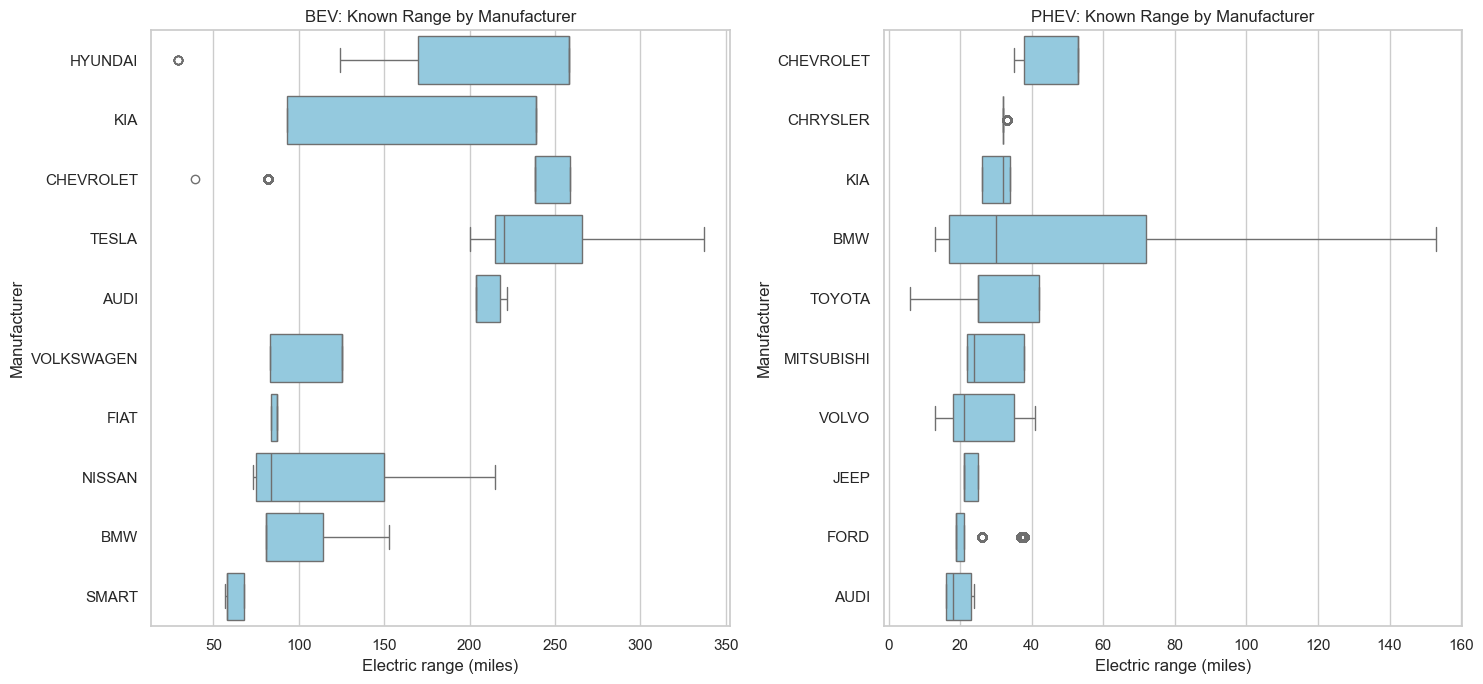

In [16]:
# Manufacturer Electric Range Summary

manufacturer_range_summary = (
    range_df.groupby(["Vehicle Type", "Make"])["Electric Range Known"]
    .agg(
        Known_Range_Count="count",
        Median_Range="median",
        Mean_Range="mean",
        Min_Range="min",
        Max_Range="max",
    )
    .round(1)
    .reset_index()
)

display(
    manufacturer_range_summary.sort_values(            
        ["Vehicle Type", "Known_Range_Count"],
        ascending=[True, False],
    ).reset_index(drop=True)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

for ax, vehicle_type in zip(axes, ["BEV", "PHEV"]):
    type_data = range_df.loc[
        range_df["Vehicle Type"].eq(vehicle_type)
    ]

    selected_makes = type_data["Make"].value_counts().head(10).index

    plot_data = type_data.loc[type_data["Make"].isin(selected_makes)]

    # Order manufacturers by median known range within each panel.
    make_order = (
        plot_data.groupby("Make")["Electric Range Known"]
        .median()
        .sort_values(ascending=False)
        .index
    )

    sns.boxplot(
        data=plot_data,
        x="Electric Range Known",
        y="Make",
        order=make_order,
        color="skyblue",
        ax=ax,
    )

    ax.set(
        title=f"{vehicle_type}: Known Range by Manufacturer",
        xlabel="Electric range (miles)",
        ylabel="Manufacturer",
    )

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "range_by_manufacturer.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

### Manufacturer Range Findings

- Among the ten BEV manufacturers with the most known range records,
  Hyundai has the highest median at 258 miles, followed by Kia at
  239 miles and Chevrolet at 238 miles. Tesla's median is 220 miles.
- Tesla has the most BEV records with known range: 25,497.
- Among the ten PHEV manufacturers with the most known range records,
  Chevrolet has the highest median electric-only range at 53 miles.
- Manufacturer summaries combine different models and model years.
  Differences therefore reflect the composition of the available records.
- Missing range information limits these comparisons. They should not
  be interpreted as rankings of manufacturers' current vehicle lineups.

### Known Electric Range by Model

Each panel compares the ten make-model pairs with the most known range
records for that vehicle type. Models are ordered by median range.

Differences within a model can reflect different model years or variants.
Models without researched range information are excluded.


BEV: ten models with the most known ranges


,Vehicle Type,Make,Model,Known_Range_Count,Median_Range,Min_Range,Max_Range
0,BEV,TESLA,MODEL 3,13832,220.0,215.0,322.0
1,BEV,NISSAN,LEAF,10667,84.0,73.0,215.0
2,BEV,TESLA,MODEL S,5991,210.0,208.0,337.0
3,BEV,CHEVROLET,BOLT EV,4622,238.0,238.0,259.0
4,BEV,TESLA,MODEL X,3331,238.0,200.0,293.0
5,BEV,TESLA,MODEL Y,2296,291.0,291.0,291.0
6,BEV,VOLKSWAGEN,E-GOLF,1079,125.0,83.0,125.0
7,BEV,KIA,NIRO,875,239.0,239.0,239.0
8,BEV,FIAT,500,787,87.0,84.0,87.0
9,BEV,AUDI,E-TRON,671,204.0,204.0,222.0



PHEV: ten models with the most known ranges


,Vehicle Type,Make,Model,Known_Range_Count,Median_Range,Min_Range,Max_Range
0,PHEV,CHEVROLET,VOLT,4819,53.0,35.0,53.0
1,PHEV,JEEP,WRANGLER,3935,21.0,21.0,25.0
2,PHEV,CHRYSLER,PACIFICA,3597,32.0,32.0,33.0
3,PHEV,TOYOTA,PRIUS PRIME,2999,25.0,25.0,39.0
4,PHEV,TOYOTA,RAV4 PRIME,2914,42.0,42.0,42.0
5,PHEV,BMW,X5,2537,30.0,13.0,40.0
6,PHEV,FORD,FUSION,1781,19.0,19.0,26.0
7,PHEV,VOLVO,XC90,1641,18.0,13.0,35.0
8,PHEV,FORD,C-MAX,1484,19.0,19.0,20.0
9,PHEV,JEEP,GRAND CHEROKEE,1337,25.0,25.0,25.0


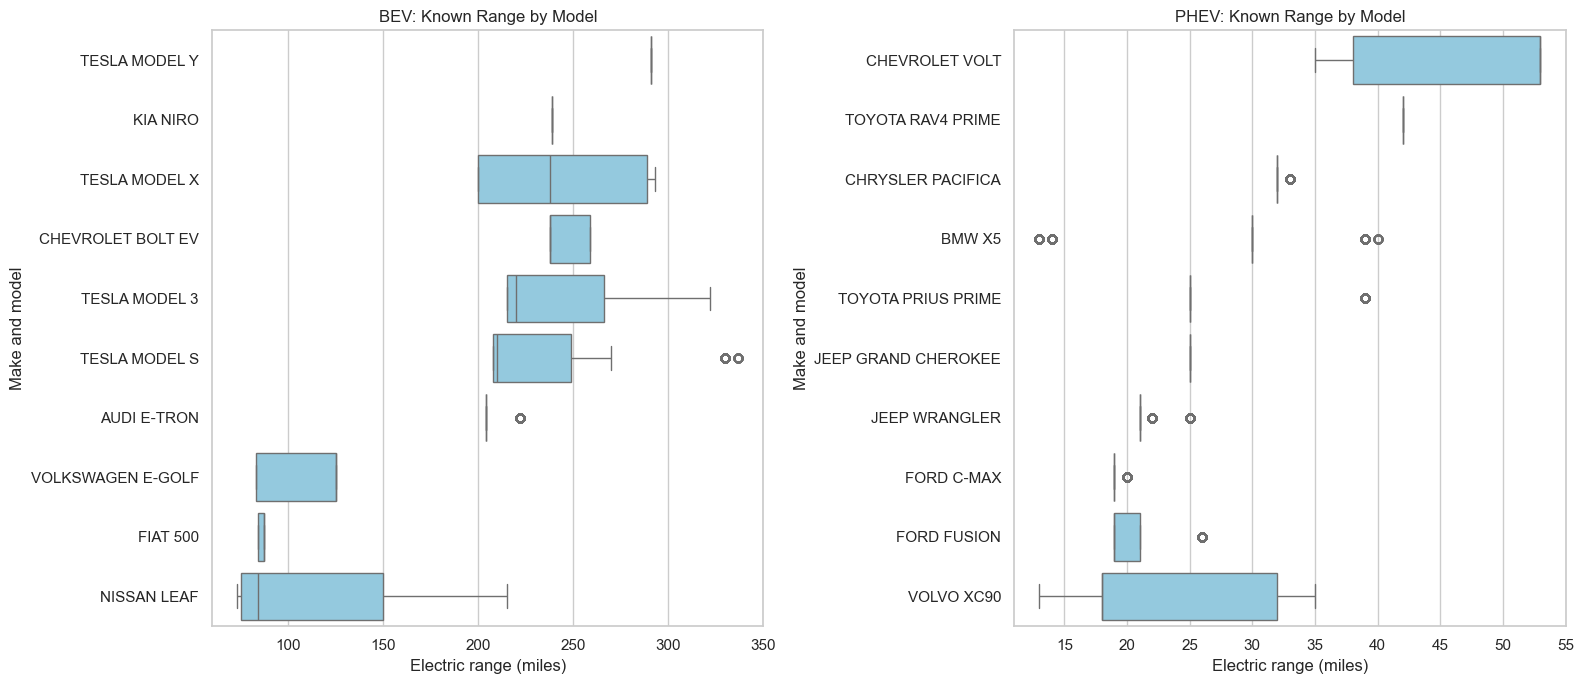

In [17]:
# Model Electric Range Summary

range_df["Vehicle Model"] = (
    range_df["Make"] + " " + range_df["Model"]
)

model_range_summary = (
    range_df.groupby(
        ["Vehicle Type", "Make", "Model"]
    )["Electric Range Known"]
    .agg(
        Known_Range_Count="count",
        Median_Range="median",
        Min_Range="min",
        Max_Range="max",
    )
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, vehicle_type in zip(axes, ["BEV", "PHEV"]):
    type_data = range_df.loc[
        range_df["Vehicle Type"].eq(vehicle_type)
    ]

    selected_models = (
        type_data["Vehicle Model"].value_counts().head(10).index
    )

    plot_data = type_data.loc[
        type_data["Vehicle Model"].isin(selected_models)
    ]

    model_order = (
        plot_data.groupby("Vehicle Model")["Electric Range Known"]
        .median()
        .sort_values(ascending=False)
        .index
    )

    sns.boxplot(
        data=plot_data,
        x="Electric Range Known",
        y="Vehicle Model",
        order=model_order,
        color="skyblue",
        ax=ax,
    )

    ax.set(
        title=f"{vehicle_type}: Known Range by Model",
        xlabel="Electric range (miles)",
        ylabel="Make and model",
    )

    print(f"\n{vehicle_type}: ten models with the most known ranges")
    display(
        model_range_summary.loc[
            model_range_summary["Vehicle Type"].eq(vehicle_type)
        ]
        .sort_values(
            ["Known_Range_Count", "Make", "Model"],
            ascending=[False, True, True],
        )
        .head(10)
        .reset_index(drop=True)
    )

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "range_by_model.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

### Model Range Findings

- Among the ten BEV models with the most known range records, Tesla
  Model Y has the highest median recorded range at 291 miles.
- Tesla Model 3 has the most known range records (13,832), with a
  median of 220 miles.
- Nissan Leaf ranges span 73–215 miles, while Tesla Model S ranges
  span 208–337 miles.
- Among the ten selected PHEV models, Chevrolet Volt has the highest
  median electric-only range at 53 miles, followed by Toyota RAV4
  Prime at 42 miles.
- Some models have a single recorded range value. Their boxplots
  collapse to a line; this does not establish that all variants or
  model years have identical ranges.
- Comparisons describe records with available range information and
  do not represent current manufacturer specifications.

## Model-Year Distribution by Manufacturer

This section compares model-year counts for the five manufacturers
with the most vehicles in the Washington dataset.

Model year is not registration year. These counts describe the vehicles
present in this snapshot, rather than annual sales, production, or
adoption rates.

Make,TESLA,CHEVROLET,NISSAN,FORD,KIA
Model Year,,,,,
1997,0,1,0,0,0
1999,0,0,0,5,0
2000,0,0,0,7,0
2002,0,0,0,0,0
2003,0,0,0,0,0
2008,22,0,0,0,0
2010,20,0,0,0,0
2011,6,67,638,0,0
2012,126,456,541,10,0


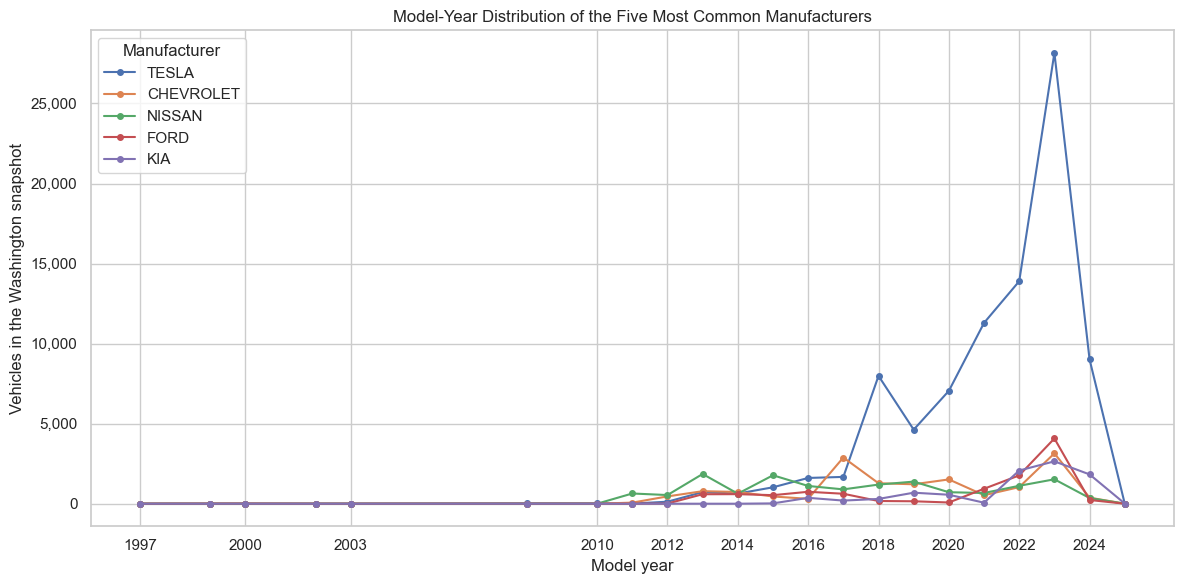

In [18]:
# Model-Year Distribution of the Five Most Common Manufacturers

selected_makes = df["Make"].value_counts().head(5).index.tolist()

year_make_counts = (
    pd.crosstab(df["Model Year"], df["Make"])
    .reindex(columns=selected_makes, fill_value=0)
    .sort_index()
)

display(year_make_counts)

fig, ax = plt.subplots(figsize=(12, 6))

for make in selected_makes:
    ax.plot(
        year_make_counts.index,
        year_make_counts[make],
        marker="o",
        markersize=4,
        label=make,
    )

ax.set(
    title="Model-Year Distribution of the Five Most Common Manufacturers",
    xlabel="Model year",
    ylabel="Vehicles in the Washington snapshot",
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:,.0f}")
)
ax.set_xticks(year_make_counts.index[::2])
ax.legend(title="Manufacturer")

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "model_year_distribution.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

### Model-Year Findings

- Tesla has the largest count among the five selected manufacturers
  for every model year from 2018 through 2024.
- The highest model-year counts occur in 2023 for Tesla (28,160),
  Chevrolet (3,146), Ford (4,075), and Kia (2,647).
- Nissan's largest count occurs in model year 2013 (1,857).
- Lower counts for 2024 and 2025 do not establish declining adoption.
  Snapshot timing and model-year availability affect these totals.
- These patterns describe the composition of this dataset, not annual
  sales, production, or future market performance.

## Known Electric Range Across Cities

We compare the ten cities with the most EV records, separating BEVs
and PHEVs and excluding unresearched ranges.

City is categorical, so a Pearson correlation using numeric city codes
would not be meaningful. Instead, we compare range distributions and
report how much range information is available in each city.

,Vehicle_Count,Known_Range_Count,Known Range (%)
City,,,
Seattle,32602,15137,46.43
Bellevue,9959,3754,37.69
Redmond,7165,2621,36.58
Vancouver,7081,3572,50.44
Bothell,6602,2193,33.22
Kirkland,5883,2420,41.14
Renton,5835,2648,45.38
Sammamish,5795,2089,36.05
Olympia,4830,2401,49.71


,City,Vehicle Type,Known_Range_Count,Median_Range,Mean_Range
0,Bellevue,BEV,2390,215.0,207.6
1,Bellevue,PHEV,1364,30.0,30.4
2,Bothell,BEV,1312,215.0,204.0
3,Bothell,PHEV,881,30.0,30.7
4,Kirkland,BEV,1490,215.0,209.4
5,Kirkland,PHEV,930,30.0,30.6
6,Olympia,BEV,1252,215.0,193.7
7,Olympia,PHEV,1149,27.0,30.8
8,Redmond,BEV,1679,215.0,204.8
9,Redmond,PHEV,942,30.0,30.5


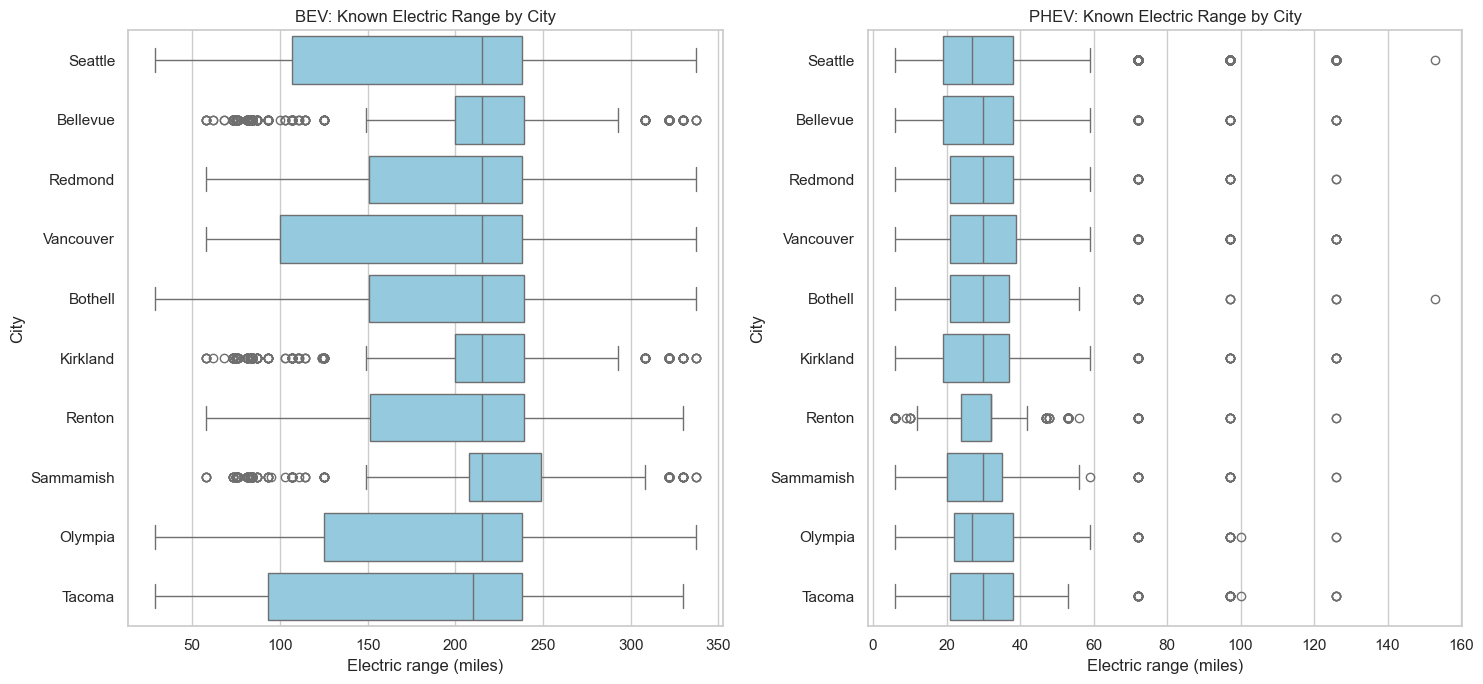

In [19]:
# City Electric Range Summary

selected_cities = city_summary.head(10)["City"].tolist()

# Report range availability alongside city vehicle counts.
city_range_coverage = (
    df.loc[df["City"].isin(selected_cities)]
    .groupby("City")
    .agg(
        Vehicle_Count=("Electric Range", "size"),
        Known_Range_Count=("Electric Range Known", "count"),
    )
    .reindex(selected_cities)
)

city_range_coverage["Known Range (%)"] = (
    city_range_coverage["Known_Range_Count"]
    / city_range_coverage["Vehicle_Count"]
    * 100
).round(2)

display(city_range_coverage)

city_range_data = range_df.loc[
    range_df["City"].isin(selected_cities)
]

city_range_summary = (
    city_range_data.groupby(["City", "Vehicle Type"])
    ["Electric Range Known"]
    .agg(
        Known_Range_Count="count",
        Median_Range="median",
        Mean_Range="mean",
    )
    .round(1)
    .reset_index()
)

display(city_range_summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

for ax, vehicle_type in zip(axes, ["BEV", "PHEV"]):
    sns.boxplot(
        data=city_range_data.loc[
            city_range_data["Vehicle Type"].eq(vehicle_type)
        ],
        x="Electric Range Known",
        y="City",
        order=selected_cities,
        color="skyblue",
        ax=ax,
    )

    ax.set(
        title=f"{vehicle_type}: Known Electric Range by City",
        xlabel="Electric range (miles)",
        ylabel="City",
    )

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "range_by_city.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

### City Range Findings

- Nine of the ten selected cities have a median known BEV range of
  215 miles; Tacoma's median is 210 miles.
- Mean known BEV ranges vary from 184.4 miles in Tacoma to 214.6 miles
  in Sammamish, reflecting differences in the available vehicle mix.
- Median known PHEV ranges vary from 27 to 32 miles.
- Range coverage varies from 33.22% in Bothell to 50.44% in Vancouver.
  Comparisons therefore exclude different proportions of each city's EVs.
- Similar medians do not establish that city and range are unrelated.
  This descriptive comparison does not isolate city effects from model,
  model year, or missing range information.

## EV Model Variety by County

Model variety is measured using distinct manufacturer-model pairs.
Vehicle counts are included for context because counties with more
vehicles have more opportunities to contain different models.

,Vehicle Count,Distinct Make-Model Pairs
County,,
King,102837,148
Snohomish,23933,136
Pierce,15739,133
Clark,11864,130
Kitsap,6686,122
Spokane,5261,120
Whatcom,4829,118
Thurston,7297,117
Skagit,2171,104


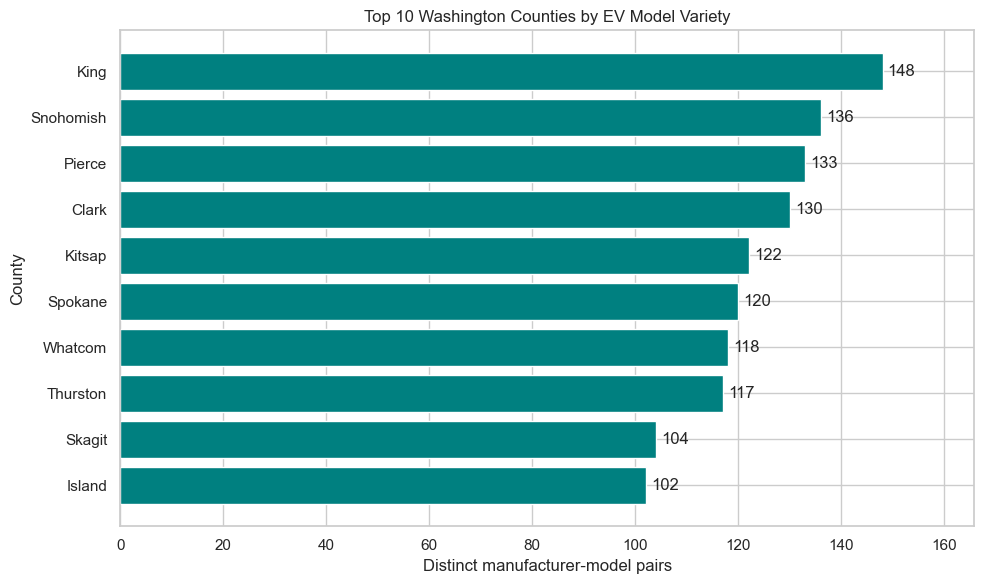

In [20]:
# County Analysis

county_vehicle_counts = (
    df.groupby("County")
    .size()
    .rename("Vehicle Count")
)

county_model_counts = (
    df[["County", "Make", "Model"]]
    .drop_duplicates()
    .groupby("County")
    .size()
    .rename("Distinct Make-Model Pairs")
)

county_summary = (
    pd.concat([county_vehicle_counts, county_model_counts], axis=1)
    .sort_values(
        ["Distinct Make-Model Pairs", "Vehicle Count"],
        ascending=[False, False],
    )
)

display(county_summary.head(10))

top_counties = county_summary.head(10)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_counties.index,
    top_counties["Distinct Make-Model Pairs"],
    color="teal",
)
ax.invert_yaxis()

ax.set(
    title="Top 10 Washington Counties by EV Model Variety",
    xlabel="Distinct manufacturer-model pairs",
    ylabel="County",
)

for position, count in enumerate(
    top_counties["Distinct Make-Model Pairs"]
):
    ax.text(count + 1, position, str(count), va="center")

ax.set_xlim(
    0, top_counties["Distinct Make-Model Pairs"].max() * 1.12
)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "county_model_variety.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

### County Model Variety Findings

- King County has the greatest observed model variety: 148 distinct
  manufacturer-model pairs, followed by Snohomish (136), Pierce (133),
  Clark (130), and Kitsap (122).
- King County also has the most EV records, with 102,837 vehicles.
- Model variety is an absolute count, not a measure adjusted for county
  population or vehicle count.
- These results do not establish why counties differ in model variety.

## Limitations

- This dataset is a single population snapshot. Model-year counts do
  not measure annual registrations, sales, or adoption rates.
- Analysis includes only records with a Washington address.
- Electric range is unresearched for 54.70% of these records.
  Known-range comparisons may not represent the full EV population.
- Positive MSRP is available for only 1.66% of records, limiting
  meaningful pricing analysis.
- Range comparisons combine model years and variants within each
  model. Recorded values do not necessarily describe current vehicles.
- Geographic comparisons are descriptive. They do not establish
  causal effects or account for differences in population, vehicle
  composition, or charging infrastructure.
- County model variety counts distinct manufacturer-model pairs,
  without adjusting for the number of vehicles in each county.

## Key Findings

### Manufacturer and Model Distribution
Tesla has the largest vehicle count in the Washington snapshot,
followed by Chevrolet, Nissan, Ford, and Kia.

### Geographic Distribution
Seattle has the most EV records (32,602), followed by Bellevue (9,959),
Redmond (7,165), Vancouver (7,081), and Bothell (6,602). These are
absolute vehicle counts, not population-adjusted adoption rates.

King County has the greatest model variety, with 148 distinct
manufacturer-model pairs.

### Recorded Electric Range
The highest known range is 337 miles, shared by 84 Tesla Model S
records. The lowest positive range is 6 miles, shared by 946 Toyota
Prius Plug-in records.

Among vehicles with known range, the median is 215 miles for BEVs
and 30 miles for PHEVs. Manufacturer and model comparisons reveal
variation within each vehicle type.

### Model-Year Patterns
Tesla has the largest count among the five selected manufacturers
for model years 2018–2024. Counts peak in 2023 for Tesla, Chevrolet,
Ford, and Kia, while Nissan peaks in 2013. These patterns describe
the snapshot's composition rather than annual market activity.

### Range Across Cities
Known BEV range medians are similar across the ten cities with the
most EV records, while means and range coverage differ. These
comparisons do not establish that geography has no relationship
with range.

### Data Quality
Unresearched electric ranges affect 54.70% of Washington records,
and MSRP is unavailable for 98.34%. Recognizing these limitations
is essential to interpreting the results.

In [21]:
import sys
import matplotlib
import seaborn

print(f"Python: {sys.version.split()[0]}")
print(f"pandas: {pd.__version__}")
print(f"matplotlib: {matplotlib.__version__}")
print(f"seaborn: {seaborn.__version__}")

Python: 3.12.2
pandas: 2.2.3
matplotlib: 3.10.8
seaborn: 0.13.2
